<a href="https://colab.research.google.com/github/ababacaryoro/nlp-course/blob/main/lab3/lab3_1_text_visualization_classical.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 3.1 – Text visualization and classical representations

**Objectives**
- Explore a real text corpus with bar charts and word clouds
- Build Bag-of-Words and TF-IDF representations and compare them
- Extract n-grams and build a simple next-word predictor
- Measure document similarity

**Dataset:** [20 Newsgroups](https://huggingface.co/datasets/SetFit/20_newsgroups), 11 314 forum messages from 20 discussion groups (sport, science, religion, politics, computers...). Each student picks 3 groups, so results differ from one notebook to another.

**Instructions**
1. Complete every cell that contains `# YOUR CODE HERE`.
2. Answer the written questions in the cells marked **Your answer**. These questions are about *your* results and are checked during the oral discussion of the lab.
3. When everything runs, follow the *Submission* section at the end.

## Setup

In [ ]:
# Google Colab only: install the libraries that Colab does not ship (about 1 minute).
# Uncomment the next line and run the cell. Nothing to do for a local installation made with `uv sync`.
# !pip install -q -r https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/requirements.txt

In [1]:
%pip install numpy pandas matplotlib seaborn nltk wordcloud scikit-learn huggingface_hub fsspec

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, re, string, urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
for resource in ["punkt", "punkt_tab", "stopwords", "wordnet"]:
    nltk.download(resource, quiet=True)
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print("Setup complete")

Setup complete


---
# Part A – Load and explore the dataset

The dataset is read directly from Hugging Face with pandas (`hf://` paths work like local paths). A local copy shipped with the lab is used if the download fails.

In [3]:
def local_file(name, lab="lab3"):
    """Path of a data file shipped with the lab; downloaded from the course repository when missing (Colab)."""
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/{lab}/data/{name}", path)
    return path

try:
    df = pd.read_json("hf://datasets/SetFit/20_newsgroups/train.jsonl", lines=True)
    print("Loaded from Hugging Face")
except Exception as e:
    print(f"Hugging Face unavailable ({type(e).__name__}), using the local copy")
    df = pd.read_csv(local_file("20_newsgroups_train.csv.gz"))

df = df.dropna(subset=["text"]).reset_index(drop=True)
print(f"Shape: {df.shape}, columns: {df.columns.tolist()}")
df["label_text"].value_counts()

C:\Users\Zhongjie Wu\anaconda3\envs\nlp_lab3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loaded from Hugging Face
Shape: (11314, 3), columns: ['text', 'label', 'label_text']


label_text
rec.sport.hockey            600
soc.religion.christian      599
rec.motorcycles             598
rec.sport.baseball          597
sci.crypt                   595
rec.autos                   594
sci.med                     594
comp.windows.x              593
sci.space                   593
comp.os.ms-windows.misc     591
sci.electronics             591
comp.sys.ibm.pc.hardware    590
misc.forsale                585
comp.graphics               584
comp.sys.mac.hardware       578
talk.politics.mideast       564
talk.politics.guns          546
alt.atheism                 480
talk.politics.misc          465
talk.religion.misc          377
Name: count, dtype: int64

In [4]:
print(f"Label: {df.iloc[0]['label_text']}")
print(df.iloc[0]["text"][:500])

Label: rec.autos
I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.


### Exercise A.1 – Choose your categories

Pick **exactly 3 categories** from the list printed above. The choice is yours; every result below depends on it.

In [7]:
print(sorted(df["label_text"].unique()))

my_categories = ["comp.graphics",
    "rec.sport.hockey",
    "sci.space"]  # YOUR CODE HERE: 3 category names copied from the list above

assert len(set(my_categories)) == 3 and all(c in df["label_text"].unique() for c in my_categories), "Pick 3 different valid categories"

df_filtered = df[df["label_text"].isin(my_categories)].reset_index(drop=True)
print(f"Selected categories: {my_categories}")
print(f"Filtered dataset: {len(df_filtered)} documents")
df_filtered["label_text"].value_counts()

['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']
Selected categories: ['comp.graphics', 'rec.sport.hockey', 'sci.space']
Filtered dataset: 1777 documents


label_text
rec.sport.hockey    600
sci.space           593
comp.graphics       584
Name: count, dtype: int64

### Question A.2 (written)

Why these 3 categories? Are they related or very different? What vocabulary differences do you expect? (3 sentences minimum)

<!-- ANSWER lab3.1-A2 -->
**Your answer:**
I chose comp.graphics, rec.sport.hockey, and sci.space to compare the vocabulary of three distinct topics. They are about computer graphics, hockey, and space. I expect words like “image” in graphics, “team” in hockey, and “orbit” in space.

*(write here)*
<!-- END ANSWER -->

---
# Part B – Preprocessing

The basic cleaning function below reuses what was done in Labs 1 and 2.

In [8]:
def preprocess_basic(text):
    """Lowercase; remove e-mails, URLs, numbers and punctuation; normalize whitespace."""
    text = str(text).lower()
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\d+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    return " ".join(text.split())

sample = "Hello! Check this: http://example.com. Email me at test@email.com. Price: $100."
print(preprocess_basic(sample))

hello check this email me at price


### Exercise B.1 – Advanced preprocessing

Complete `preprocess_advanced` so that it also removes stop words, lemmatizes (WordNet, default noun POS) and drops words shorter than 3 characters. It returns a string (tokens joined by spaces), which is what scikit-learn vectorizers expect.

In [9]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def preprocess_advanced(text):
    """Basic cleaning + stop word removal + lemmatization + minimum length 3. Returns a string."""
    # YOUR CODE HERE
    # 1. preprocess_basic
    text = preprocess_basic(text)
    # 2. tokenize
    tokens = word_tokenize(text)
    # 3. remove stop words
    tokens = [
        word for word in tokens
        if word not in stop_words
    ]
    # 4. lemmatize
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]
    # 5. keep words with at least 3 characters
    tokens = [
        word for word in tokens
        if len(word) >= 3
    ]
    # 6. join back into a string
    return " ".join(tokens)

sample = "The cats are running quickly towards the beautiful gardens. Email: test@mail.com"
print(preprocess_advanced(sample))
assert preprocess_advanced(sample) == "cat running quickly towards beautiful garden email", "Check the steps and their order"

cat running quickly towards beautiful garden email


In [10]:
df_filtered["text_clean"] = df_filtered["text"].apply(preprocess_advanced)
print(df_filtered.iloc[0]["text_clean"][:300])

weitek address phone number like get information chip


---
# Part C – Visualization

## C.1 Most frequent words per category

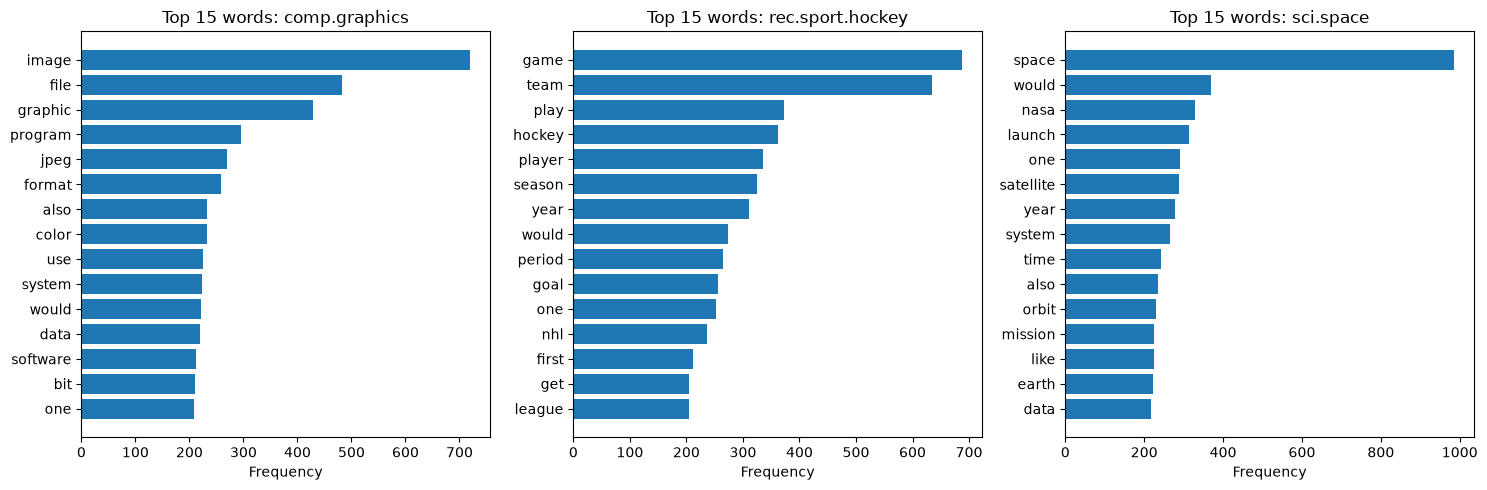

In [11]:
def get_top_words(texts, n=15):
    """n most common words in a list of cleaned texts."""
    return Counter(" ".join(texts).split()).most_common(n)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, category in zip(axes, my_categories):
    texts = df_filtered.loc[df_filtered["label_text"] == category, "text_clean"]
    words, counts = zip(*get_top_words(texts, 15))
    ax.barh(words, counts)
    ax.invert_yaxis()
    ax.set_title(f"Top 15 words: {category}")
    ax.set_xlabel("Frequency")
plt.tight_layout()
plt.show()

### Question C.1 (written)

1. Which words are specific to each category? (at least 2 per category)
2. Which words are shared by the 3 categories, and why?
3. Could you guess the topic of each category from its top words only?

<!-- ANSWER lab3.1-C1 -->
**Your answer:**
1.Graphics texts use “image” and “file.” Hockey texts use “game” and “team.” Space texts use “space” and “nasa.”

2.“One” and “would” appear in all three categories because they are common words used in discussions.

3.Yes, I can guess the topics because the top words clearly relate to each category.
*(write here)*
<!-- END ANSWER -->

## C.2 Word clouds

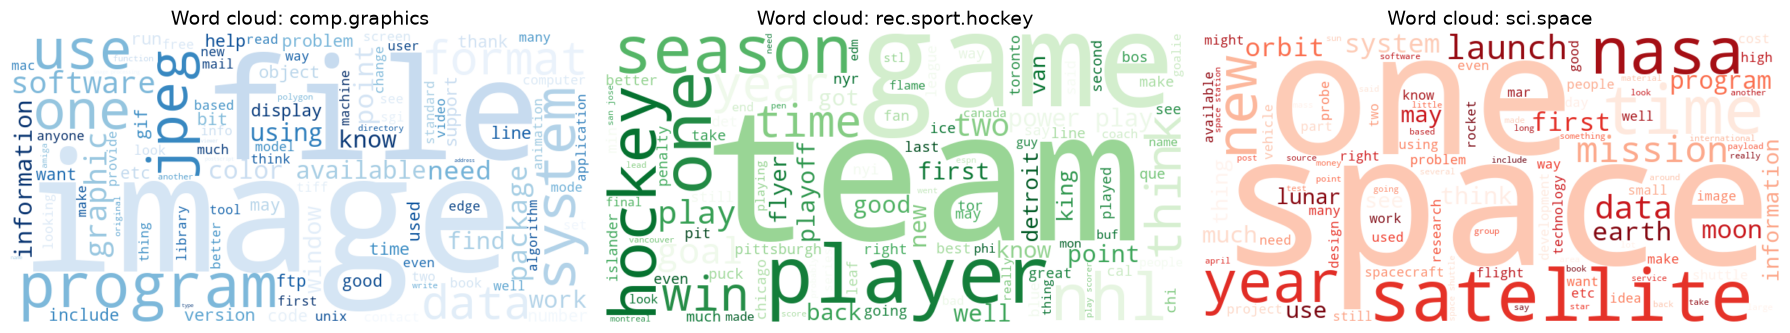

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, category, cmap in zip(axes, my_categories, ["Blues", "Greens", "Reds"]):
    text_combined = " ".join(df_filtered.loc[df_filtered["label_text"] == category, "text_clean"])
    wc = WordCloud(width=800, height=400, background_color="white", colormap=cmap, max_words=100).generate(text_combined)
    ax.imshow(wc.to_image(), interpolation="bilinear")
    ax.set_title(f"Word cloud: {category}", fontsize=14)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Exercise C.2 – Word cloud with a custom shape

`WordCloud` accepts a `mask` (a 2-D array where 255 = area to fill, 0 = area to leave blank). The cell below builds a circular mask; any black-and-white silhouette image opened with `PIL.Image` and converted to an array works as well.

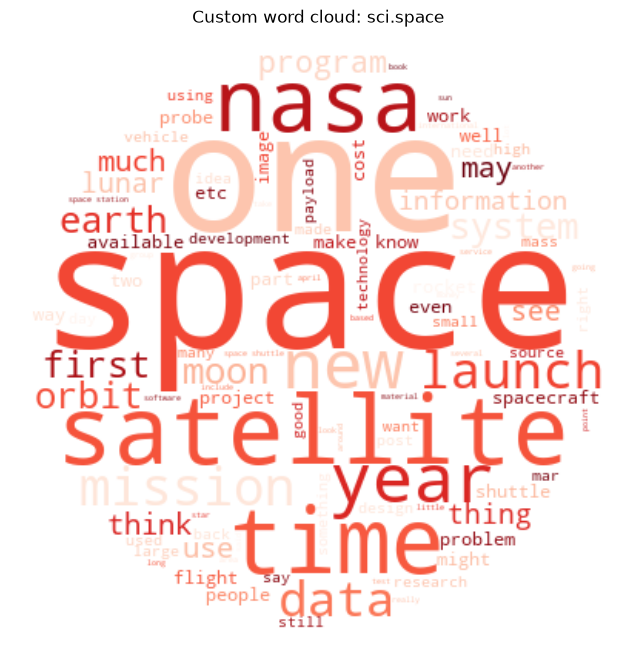

In [13]:
from PIL import Image

def circle_mask(size=400):
    y, x = np.ogrid[:size, :size]
    center, r = size // 2, size // 2 - 10
    mask = np.full((size, size), 255, dtype=np.uint8)   # 255 = masked out
    mask[(x - center) ** 2 + (y - center) ** 2 <= r ** 2] = 0   # 0 = draw here
    return mask

mask = circle_mask()
# To use your own image instead:  mask = np.array(Image.open("my_shape.png").convert("L"))

selected_category = "sci.space"  # YOUR CODE HERE: one of your categories
texts = df_filtered.loc[df_filtered["label_text"] == selected_category, "text_clean"]
wordcloud_masked = WordCloud(
    mask=mask,
    background_color="white",
    colormap="Reds",
    max_words=100,
    random_state=42
).generate(text_combined)    # YOUR CODE HERE: WordCloud(..., mask=mask, ...).generate(...)

plt.figure(figsize=(8, 8))
plt.imshow(wordcloud_masked.to_image(), interpolation="bilinear")
plt.title(f"Custom word cloud: {selected_category}")
plt.axis("off")
plt.show()

---
# Part D – Bag of Words

In [14]:
sample_docs = ["I love machine learning", "Machine learning is great", "I love deep learning too"]

bow_vectorizer = CountVectorizer()
bow_matrix = bow_vectorizer.fit_transform(sample_docs)

print("Vocabulary:", bow_vectorizer.get_feature_names_out())
bow_df = pd.DataFrame(bow_matrix.toarray(), columns=bow_vectorizer.get_feature_names_out())
bow_df

Vocabulary: ['deep' 'great' 'is' 'learning' 'love' 'machine' 'too']


,deep,great,is,learning,love,machine,too
0,0,0,0,1,1,1,0
1,0,1,1,1,0,1,0
2,1,0,0,1,1,0,1


### Exercise D.1 – Bag of Words of your corpus

In [15]:
# Build the BoW matrix of df_filtered["text_clean"] with max_features=1000, min_df=5, max_df=0.95
bow_vectorizer_full = CountVectorizer(
    max_features=1000,
    min_df=5,
    max_df=0.95
)
  # YOUR CODE HERE
bow_matrix_full = bow_vectorizer_full.fit_transform(
    df_filtered["text_clean"]
)      # YOUR CODE HERE

print(f"BoW matrix shape: {bow_matrix_full.shape}")
print(f"Sparsity: {100 * (1 - bow_matrix_full.nnz / np.prod(bow_matrix_full.shape)):.1f}% of zeros")
print(f"First 20 words: {bow_vectorizer_full.get_feature_names_out()[:20]}")
assert bow_matrix_full.shape == (len(df_filtered), 1000), "Check the vectorizer parameters"

BoW matrix shape: (1777, 1000)
Sparsity: 96.9% of zeros
First 20 words: ['abc' 'able' 'access' 'according' 'acquired' 'activity' 'actually' 'adam'
 'add' 'addition' 'additional' 'address' 'adirondack' 'advance'
 'advantage' 'aerospace' 'agency' 'ago' 'agree' 'ahl']


### Exercise D.2 – Document similarity

In [17]:
# 1. Compute the cosine similarity matrix between all documents (BoW vectors)
# 2. Find the most similar pair of distinct documents (ignore the diagonal)
similarity_matrix = cosine_similarity(bow_matrix_full)   # YOUR CODE HERE
search_matrix = similarity_matrix.copy()
np.fill_diagonal(search_matrix, -np.inf)
most_similar_idx = np.unravel_index(
    np.argmax(search_matrix),
    search_matrix.shape
)    # YOUR CODE HERE: (i, j) tuple, i != j
most_similar_score = float(
    similarity_matrix[most_similar_idx]
)  # YOUR CODE HERE

print(f"Similarity matrix shape: {similarity_matrix.shape}")
print(f"Most similar documents: {most_similar_idx}, score = {most_similar_score:.3f}")
assert similarity_matrix.shape == (len(df_filtered), len(df_filtered)) and most_similar_idx[0] != most_similar_idx[1]

for k, idx in enumerate(most_similar_idx, 1):
    print(f"\nDocument {k} ({df_filtered.iloc[idx]['label_text']}):")
    print(df_filtered.iloc[idx]["text"][:300])

Similarity matrix shape: (1777, 1777)
Most similar documents: (542, 993), score = 1.000

Document 1 (sci.space):
The most current orbital elements from the NORAD two-line element sets are
carried on the Celestial BBS, (513) 427-0674, and are updated daily (when
possible).  Documentation and tracking software are also available on this
system.  As a service to the satellite user community, the most current
elem

Document 2 (sci.space):
The most current orbital elements from the NORAD two-line element sets are
carried on the Celestial BBS, (513) 427-0674, and are updated daily (when
possible).  Documentation and tracking software are also available on this
system.  As a service to the satellite user community, the most current
elem


### Question D.3 (written)

1. Are the two most similar documents from the same category?
2. Reading them, what makes them similar?
3. Is BoW cosine similarity meaningful here? Why?

<!-- ANSWER lab3.1-D3 -->
**Your answer:**
Both documents are from rec.sport.hockey. They are player price lists from different weeks and share many player names. BoW finds their shared words, but it misses price changes because numbers were removed during cleaning.
*(write here)*
<!-- END ANSWER -->

---
# Part E – TF-IDF

In [18]:
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(sample_docs)
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf_vectorizer.get_feature_names_out()).round(3)
tfidf_df

,deep,great,is,learning,love,machine,too
0,0.000,0.000,0.000,0.481,0.620,0.620,0.000
1,0.000,0.584,0.584,0.345,0.000,0.445,0.000
2,0.584,0.000,0.000,0.345,0.445,0.000,0.584


In [19]:
print("Scores of the word 'learning' (present in every document):")
print("  BoW:   ", bow_df["learning"].tolist())
print("  TF-IDF:", tfidf_df["learning"].tolist(), "-> lower weight for a word shared by all documents")

Scores of the word 'learning' (present in every document):
  BoW:    [1, 1, 1]
  TF-IDF: [0.481, 0.345, 0.345] -> lower weight for a word shared by all documents


### Exercise E.1 – TF-IDF of your corpus and top words per category

In [20]:
tfidf_vectorizer_full = TfidfVectorizer(
    max_features=1000,
    min_df=5,
    max_df=0.95
)  # YOUR CODE HERE (same parameters as the BoW)
tfidf_matrix_full = tfidf_vectorizer_full.fit_transform(
    df_filtered["text_clean"]
)     # YOUR CODE HERE
print(f"TF-IDF matrix shape: {tfidf_matrix_full.shape}")

def get_top_tfidf_words(category, n=10):
    """Words with the highest mean TF-IDF over the documents of a category."""
    # YOUR CODE HERE
    # 1. indices of the documents of this category
    category_mask = (
        df_filtered["label_text"] == category
    ).to_numpy()
    # 2. their TF-IDF rows
    category_matrix = tfidf_matrix_full[category_mask]
    # 3. mean score of each word over these rows
    mean_scores = np.asarray(
        category_matrix.mean(axis=0)
    ).ravel()
    # 4. the n words with the highest mean
    top_indices = np.argsort(mean_scores)[::-1][:n]

    words = tfidf_vectorizer_full.get_feature_names_out()

    return [
        (words[i], float(mean_scores[i]))
        for i in top_indices
    ]
    pass

for category in my_categories:
    print(f"\nTop TF-IDF words for '{category}':")
    print(get_top_tfidf_words(category, 10))
assert len(get_top_tfidf_words(my_categories[0], 10)) == 10

TF-IDF matrix shape: (1777, 1000)

Top TF-IDF words for 'comp.graphics':
[('file', 0.052488840005671764), ('graphic', 0.047765516187845), ('image', 0.04191955523888992), ('thanks', 0.036779288640921434), ('know', 0.031546027018522625), ('program', 0.031150341646206753), ('anyone', 0.02961629835653078), ('would', 0.028566924530884438), ('format', 0.026658436298638163), ('color', 0.025483203274407968)]

Top TF-IDF words for 'rec.sport.hockey':
[('game', 0.07316493685644918), ('team', 0.05906756450855305), ('player', 0.04267454043482732), ('hockey', 0.04174057926574946), ('play', 0.03385941022674224), ('year', 0.03146788250808049), ('season', 0.03126656166706454), ('would', 0.02975558808875069), ('nhl', 0.02662892547368999), ('think', 0.026189068438641414)]

Top TF-IDF words for 'sci.space':
[('space', 0.06924931715332333), ('would', 0.04002238891554612), ('one', 0.028803215694665204), ('like', 0.028102835023212216), ('nasa', 0.026711154184760225), ('launch', 0.02529995001954947), ('orbit

### Question E.2 (written)

Compare with the word counts of Part C:
1. Which words appear in the TF-IDF top 10 but not in the count top 15?
2. Which words appear in the count top 15 but not in the TF-IDF top 10?
3. Which representation captures the *topic* of each category better? Why?

<!-- ANSWER lab3.1-E2 -->
**Your answer:**
Word counts show the topics more clearly in these results. TF-IDF still gives high scores to general words such as “thanks,” “know,” and “think.”
*(write here)*
<!-- END ANSWER -->

---
# Part F – N-grams and next-word prediction

In [21]:
from nltk import ngrams

tokens = "I love natural language processing and machine learning".split()
print("Bigrams: ", list(ngrams(tokens, 2)))
print("Trigrams:", list(ngrams(tokens, 3)))

# CountVectorizer can also build n-gram features
bigram_vectorizer = CountVectorizer(ngram_range=(2, 2))
bigram_vectorizer.fit(["I love machine learning", "Machine learning is great"])
print("Bigram features:", bigram_vectorizer.get_feature_names_out())

Bigrams:  [('I', 'love'), ('love', 'natural'), ('natural', 'language'), ('language', 'processing'), ('processing', 'and'), ('and', 'machine'), ('machine', 'learning')]
Trigrams: [('I', 'love', 'natural'), ('love', 'natural', 'language'), ('natural', 'language', 'processing'), ('language', 'processing', 'and'), ('processing', 'and', 'machine'), ('and', 'machine', 'learning')]
Bigram features: ['is great' 'learning is' 'love machine' 'machine learning']


### Exercise F.1 – Most frequent bigrams per category

In [24]:
def top_bigrams(texts, n=15):
    """(bigram, count) list of the n most frequent bigrams in the texts."""
    # YOUR CODE HERE
    # 1. CountVectorizer(ngram_range=(2, 2), min_df=3) fitted on the texts
    vectorizer = CountVectorizer(
        ngram_range=(2, 2),
        min_df=3
    )

    matrix = vectorizer.fit_transform(texts)
    # 2. sum the columns to count each bigram
    counts = np.asarray(
        matrix.sum(axis=0)
    ).ravel()

    bigrams = vectorizer.get_feature_names_out()

    top_indices = np.argsort(counts)[::-1][:n]
    # 3. return the n most frequent (bigram, count)
    return [
        (bigrams[i], int(counts[i]))
        for i in top_indices
    ]

for category in my_categories:
    texts = df_filtered.loc[df_filtered["label_text"] == category, "text_clean"]
    print(f"\nTop bigrams for '{category}':")
    for bigram, count in top_bigrams(texts, 15):
        print(f"  {bigram}: {count}")
assert len(top_bigrams(df_filtered["text_clean"], 5)) == 5


Top bigrams for 'comp.graphics':
  image processing: 58
  comp graphic: 49
  file format: 43
  computer graphic: 42
  edu pub: 41
  thanks advance: 38
  would like: 38
  source code: 37
  anyone know: 35
  ray tracer: 33
  anonymous ftp: 31
  ftp site: 29
  virtual reality: 29
  image file: 26
  bit image: 25

Top bigrams for 'rec.sport.hockey':
  power play: 145
  play scorer: 63
  san jose: 62
  third period: 58
  new jersey: 56
  second period: 56
  los angeles: 55
  first period: 53
  hockey league: 52
  tampa bay: 50
  stanley cup: 49
  new york: 45
  last year: 42
  brind amour: 42
  maple leaf: 40

Top bigrams for 'sci.space':
  space station: 69
  space shuttle: 66
  sci space: 58
  anonymous ftp: 38
  commercial space: 32
  remote sensing: 32
  gamma ray: 28
  launch vehicle: 27
  national space: 26
  sci astro: 25
  air force: 24
  nasa ames: 24
  nasa gov: 24
  space technology: 23
  pub space: 21


### Exercise F.2 – A bigram next-word predictor

The probability of a word given the previous one is estimated by counting: P(w2 | w1) = count(w1, w2) / count(w1).

In [26]:
class BigramPredictor:
    def __init__(self):
        self.bigram_counts = {}   # {word1: Counter({word2: count, ...})}
        self.unigram_counts = Counter()

    def train(self, texts):
        """Count unigrams and bigrams over a list of texts (strings)."""
        for text in texts:
            tokens = text.split()
            self.unigram_counts.update(tokens)
            for first, second in zip(tokens, tokens[1:]):
                self.bigram_counts.setdefault(
                    first, Counter()
                )[second] += 1
        # YOUR CODE HERE

    def predict_next(self, word, top_n=5):
        """Return the top_n (next_word, probability) pairs for a word."""
        # YOUR CODE HERE
        word = word.lower()

        if word not in self.bigram_counts:
            return []

        total = self.unigram_counts[word]
        return [(next_word, count / total)
            for next_word, count
            in self.bigram_counts[word].most_common(top_n)]

# Sanity check on a tiny corpus
toy = BigramPredictor()
toy.train(["the cat sat on the mat", "the cat ate the fish"])
print(toy.predict_next("the"))
assert toy.predict_next("the")[0] == ("cat", 0.5), "P(cat | the) should be 2/4"
assert toy.predict_next("cat") == [("sat", 0.5), ("ate", 0.5)] or toy.predict_next("cat") == [("ate", 0.5), ("sat", 0.5)]

predictor = BigramPredictor()
predictor.train(df_filtered["text_clean"])

[('cat', 0.5), ('mat', 0.25), ('fish', 0.25)]


In [27]:
# Choose 5 words related to YOUR categories and look at the predictions
test_words = ["image", "file", "team", "space", "nasa"]  # YOUR CODE HERE

for word in test_words:
    print(f"\n'{word}' ->")
    for next_word, prob in predictor.predict_next(word.lower(), top_n=5):
        print(f"  {next_word}: {prob:.3f}")


'image' ->
  processing: 0.073
  file: 0.032
  format: 0.027
  quality: 0.025
  analysis: 0.018

'file' ->
  format: 0.081
  pub: 0.019
  msdos: 0.017
  available: 0.013
  ftp: 0.013

'team' ->
  would: 0.022
  play: 0.016
  top: 0.015
  record: 0.013
  get: 0.013

'space' ->
  shuttle: 0.066
  station: 0.065
  technology: 0.022
  program: 0.020
  science: 0.018

'nasa' ->
  gov: 0.098
  ames: 0.070
  center: 0.034
  budget: 0.020
  lewis: 0.017


### Question F.3 (written)

1. Give 2 sensible predictions and 2 poor ones.
2. What are the limits of a bigram model?
3. How could the predictor be improved? (3 ideas)

<!-- ANSWER lab3.1-F3 -->
**Your answer:**
1. “Image processing” and “space shuttle” are sensible predictions. “Team would” and “team get” are less natural on their own.
2. The bigram model uses only the previous word. It cannot understand the whole sentence.
3. We could use more training data, use longer contexts such as trigrams, and apply smoothing.
*(write here)*
<!-- END ANSWER -->

---
# Part G – Document similarity heatmap

TF-IDF cosine similarity between 30 documents (10 per category).

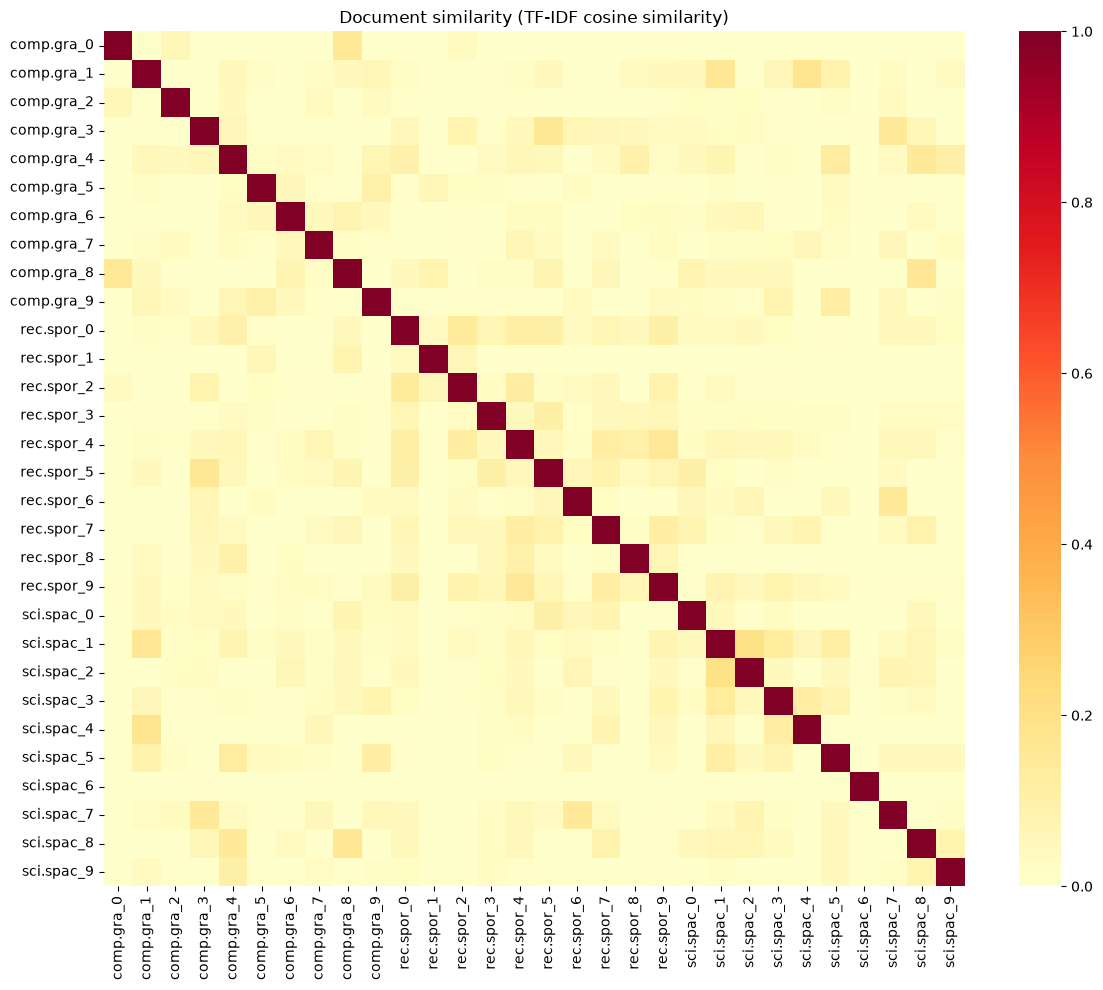

In [28]:
df_sampled = pd.concat([df_filtered[df_filtered["label_text"] == c].sample(n=10, random_state=42) for c in my_categories]).reset_index(drop=True)
tfidf_sampled = TfidfVectorizer(max_features=500).fit_transform(df_sampled["text_clean"])
similarity_sampled = cosine_similarity(tfidf_sampled)

labels = [f"{cat[:8]}_{i % 10}" for i, cat in enumerate(df_sampled["label_text"])]
plt.figure(figsize=(12, 10))
sns.heatmap(similarity_sampled, xticklabels=labels, yticklabels=labels, cmap="YlOrRd")
plt.title("Document similarity (TF-IDF cosine similarity)")
plt.tight_layout()
plt.show()

### Question G.1 (written)

1. Do documents of the same category form brighter blocks along the diagonal?
2. Which pair of categories is the most similar? The least similar?
3. Any surprising similarity between documents of different categories? What could explain it?

<!-- ANSWER lab3.1-G1 -->
**Your answer:**
1. The same-category blocks are weak, especially for graphics.
2. Graphics and space are the most similar on average. Graphics and hockey are the least similar.
3. Some documents from different categories are similar because they share general words. Short messages can also produce surprising similarities.
*(write here)*
<!-- END ANSWER -->

---
## Summary

- Word counts and word clouds give a first picture of a corpus, after cleaning.
- Bag of Words counts words; TF-IDF down-weights words shared by many documents.
- N-grams capture short sequences; a bigram model is the simplest language model.
- Cosine similarity on these vectors measures lexical overlap, not meaning. Lab 3.2 moves to embeddings.

---

## Submission

1. Run the whole notebook from top to bottom (`Kernel > Restart & Run All`) and check that no cell fails.
2. Keep the outputs, save the notebook and commit it in your course repository (`nlp-course-LASTNAME`), in the same folder as in the course repository.
3. Push, then send an e-mail to the teacher to say that the work is ready. The link to the repository is only needed in your first e-mail.